# 🐱 Gatti in rifugio: chi viene adottato prima?
**Francesco Autorino – Data Analyst**

📊 Dati: Austin Animal Center (Texas), ottobre 2013 – maggio 2025.
❓ Domanda: **quali gatti vengono adottati, e quanto aspettano?**

Le 5 domande più piccole:
1. 🚪 Come escono i gatti dal rifugio?
2. 🍼 L'età conta?
3. 🐈‍⬛ I gatti neri vengono adottati meno?
4. 🌸 Ci sono mesi con più gattini e più adozioni?
5. 🏥 Il modo in cui arriva il gatto conta?

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from scipy import stats
from pathlib import Path
DATI = Path('..') / '02Dati' / '2Puliti' / 'gatti_ingressi.csv'
G = Path('grafici'); G.mkdir(exist_ok=True)
d = pd.read_csv(DATI, parse_dates=['data_ingresso', 'data_uscita'])
c = d[d['esito'] != 'Senza esito registrato'].copy()   # solo ingressi con un esito
a = c[c['adottato']]                                   # solo le adozioni
# stile dei grafici: fondo chiaro, griglia leggera, un solo colore per serie
BLU, NERO, INK, MUTED, GRID, SURF = '#2a78d6', '#3a3a38', '#0b0b0b', '#52514e', '#e4e3df', '#fcfcfb'
plt.rcParams.update({'figure.facecolor': SURF, 'axes.facecolor': SURF, 'axes.edgecolor': GRID, 'axes.labelcolor': MUTED,
    'xtick.color': MUTED, 'ytick.color': MUTED, 'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.titleweight': 'bold', 'axes.titlesize': 13,
    'axes.titlecolor': INK, 'axes.titlelocation': 'left', 'font.size': 11, 'figure.dpi': 110})
def salva(f, nome): f.tight_layout(); f.savefig(G / nome, dpi=150, bbox_inches='tight'); plt.show()
print(f"{len(d):,} ingressi · {d['id_gatto'].nunique():,} gatti diversi · {len(c):,} con un esito".replace(',', '.'))

69.313 ingressi · 66.239 gatti diversi · 68.559 con un esito


## 🚪 1. Come escono i gatti dal rifugio?

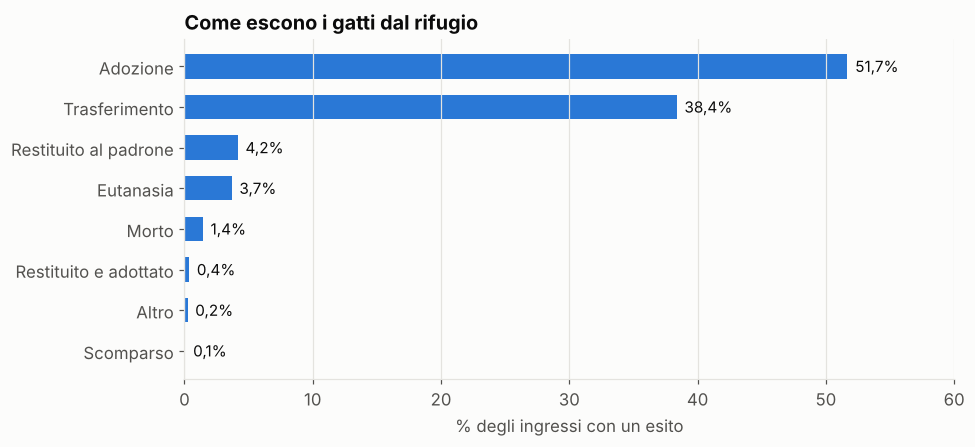

Attesa prima dell'adozione: mediana 25.2 giorni · media 38.5


In [2]:
e = c['esito'].value_counts(normalize=True).mul(100).sort_values()
f, ax = plt.subplots(figsize=(9, 4.2))
ax.barh(e.index, e.values, color=BLU, height=0.6); ax.grid(axis='y', visible=False)
for i, v in enumerate(e.values): ax.text(v + 0.6, i, f'{v:.1f}%'.replace('.', ','), va='center', color=INK, fontsize=10)
ax.set_title('Come escono i gatti dal rifugio'); ax.set_xlabel('% degli ingressi con un esito'); ax.set_xlim(0, 60)
salva(f, '01_esiti.png')
print('Attesa prima dell\'adozione: mediana', round(a['giorni_rifugio'].median(), 1), 'giorni · media', round(a['giorni_rifugio'].mean(), 1))

📌 **Più di 1 gatto su 2 viene adottato (51,7%).**
Quasi 4 su 10 vengono **trasferiti** a un rifugio partner.
In mezzo ci sono **25 giorni** (mediana) di attesa prima dell'adozione.

## 🍼 2. L'età conta?

,ingressi,perc_adottati,giorni_mediana
fascia_eta,,,
Cucciolo (<6 mesi),41731,58.2,30.2
Giovane (6-12 mesi),3520,52.9,9.1
Adulto (1-7 anni),19510,39.6,17.8
Anziano (7+ anni),3798,41.3,27.1


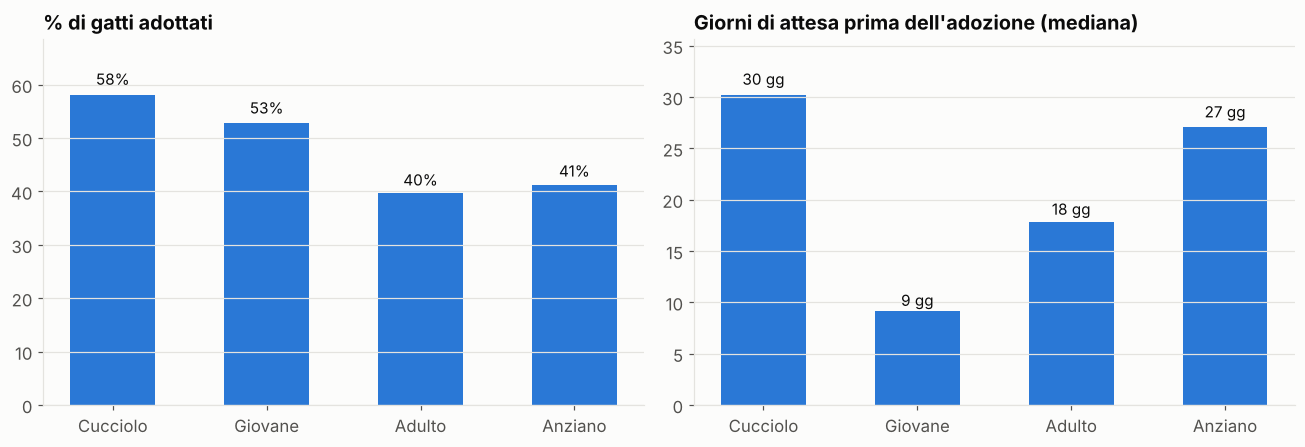

In [3]:
ordine = ['Cucciolo (<6 mesi)', 'Giovane (6-12 mesi)', 'Adulto (1-7 anni)', 'Anziano (7+ anni)']
t = c[c['fascia_eta'].isin(ordine)].groupby('fascia_eta').agg(ingressi=('id_gatto', 'size'), perc_adottati=('adottato', 'mean'))
t['perc_adottati'] *= 100
t['giorni_mediana'] = a.groupby('fascia_eta')['giorni_rifugio'].median()
t = t.loc[ordine]; display(t.round(1))
f, ax = plt.subplots(1, 2, figsize=(12, 4.2))
etich = [o.split(' (')[0] for o in ordine]
for k, (col, tit, fmt) in enumerate([('perc_adottati', '% di gatti adottati', '{:.0f}%'), ('giorni_mediana', 'Giorni di attesa prima dell\'adozione (mediana)', '{:.0f} gg')]):
    ax[k].bar(etich, t[col], color=BLU, width=0.55); ax[k].grid(axis='x', visible=False); ax[k].set_title(tit)
    for i, v in enumerate(t[col]): ax[k].text(i, v * 1.02, fmt.format(v), ha='center', va='bottom', color=INK, fontsize=10)
    ax[k].set_ylim(0, t[col].max() * 1.18)
salva(f, '02_eta.png')

📌 I **cuccioli** vengono adottati di più (58%), ma aspettano **30 giorni**:
devono crescere e pesare abbastanza prima di poter andare via.
📌 I **giovani** (6-12 mesi) sono i più veloci: **9 giorni**.
📌 **Adulti e anziani** vengono adottati meno (circa 40%). Gli anziani aspettano **27 giorni**.

## 🐈‍⬛ 3. I gatti neri vengono adottati meno?

gruppo,Altri colori,Nero
fascia_eta,,
Cucciolo (<6 mesi),58.6,55.2
Giovane (6-12 mesi),53.4,49.2
Adulto (1-7 anni),40.0,36.9
Anziano (7+ anni),41.9,35.9


gruppo,Altri colori,Nero
fascia_eta,,
Cucciolo (<6 mesi),30.0,33.8
Giovane (6-12 mesi),9.1,11.2
Adulto (1-7 anni),17.1,23.1
Anziano (7+ anni),25.9,40.2


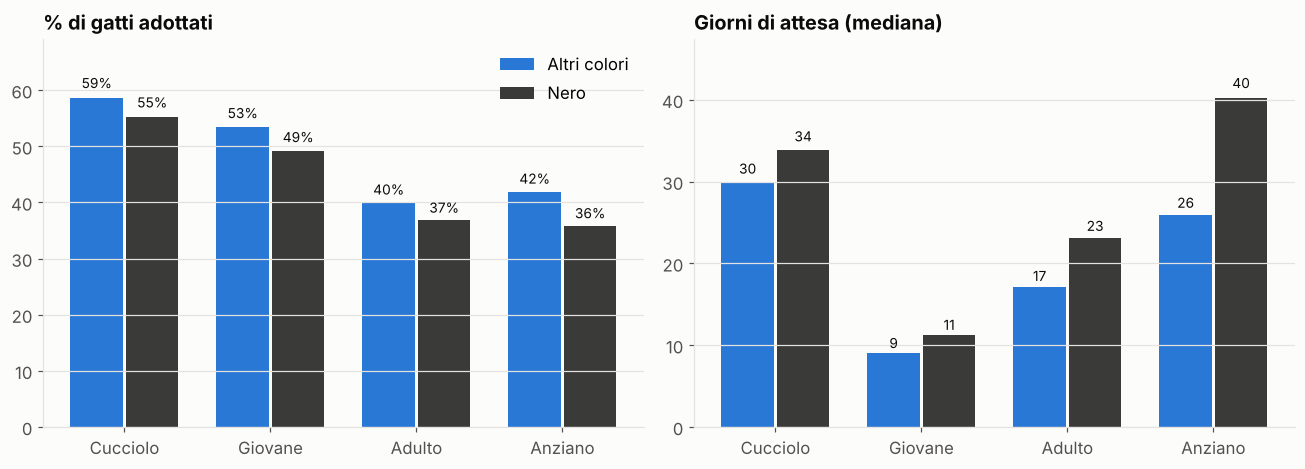

Chi-quadro adozione nero vs altri: p = 7.5e-07
Mann-Whitney giorni di attesa nero vs altri: p = 1.1e-18


In [4]:
c['gruppo'] = np.where(c['gatto_nero'], 'Nero', 'Altri colori'); a = c[c['adottato']]
tn = c[c['fascia_eta'].isin(ordine)].groupby(['fascia_eta', 'gruppo'])['adottato'].mean().unstack().loc[ordine] * 100
gn = a[a['fascia_eta'].isin(ordine)].groupby(['fascia_eta', 'gruppo'])['giorni_rifugio'].median().unstack().loc[ordine]
display(tn.round(1)); display(gn.round(1))
f, ax = plt.subplots(1, 2, figsize=(12, 4.4)); x = np.arange(len(ordine)); w = 0.36
for k, (tab, tit, fmt) in enumerate([(tn, '% di gatti adottati', '{:.0f}%'), (gn, 'Giorni di attesa (mediana)', '{:.0f}')]):
    for j, (g, col) in enumerate([('Altri colori', BLU), ('Nero', NERO)]):
        b = ax[k].bar(x + (j - 0.5) * (w + 0.02), tab[g], width=w, color=col, label=g)
        for xi, v in zip(x, tab[g]): ax[k].text(xi + (j - 0.5) * (w + 0.02), v * 1.02, fmt.format(v), ha='center', va='bottom', fontsize=9, color=INK)
    ax[k].set_xticks(x, etich); ax[k].grid(axis='x', visible=False); ax[k].set_title(tit); ax[k].set_ylim(0, tab.values.max() * 1.18)
ax[0].legend(frameon=False, loc='upper right')
salva(f, '03_gatti_neri.png')
# test statistici
tab = pd.crosstab(c['gruppo'], c['adottato']); chi2, p, *_ = stats.chi2_contingency(tab)
u, p2 = stats.mannwhitneyu(a.loc[a['gruppo'] == 'Nero', 'giorni_rifugio'], a.loc[a['gruppo'] != 'Nero', 'giorni_rifugio'])
print(f'Chi-quadro adozione nero vs altri: p = {p:.1e}')
print(f'Mann-Whitney giorni di attesa nero vs altri: p = {p2:.1e}')

📌 **Sì, ma la differenza è piccola.**
In **ogni** fascia d'età i gatti neri vengono adottati **3-6 punti in meno**.
E aspettano di più: per gli **anziani neri** l'attesa sale da 26 a **40 giorni**.
📌 I test statistici (chi-quadro e Mann-Whitney) dicono che la differenza **non è dovuta al caso** (p < 0,001).

## 🌸 4. Ci sono mesi con più gattini e più adozioni?

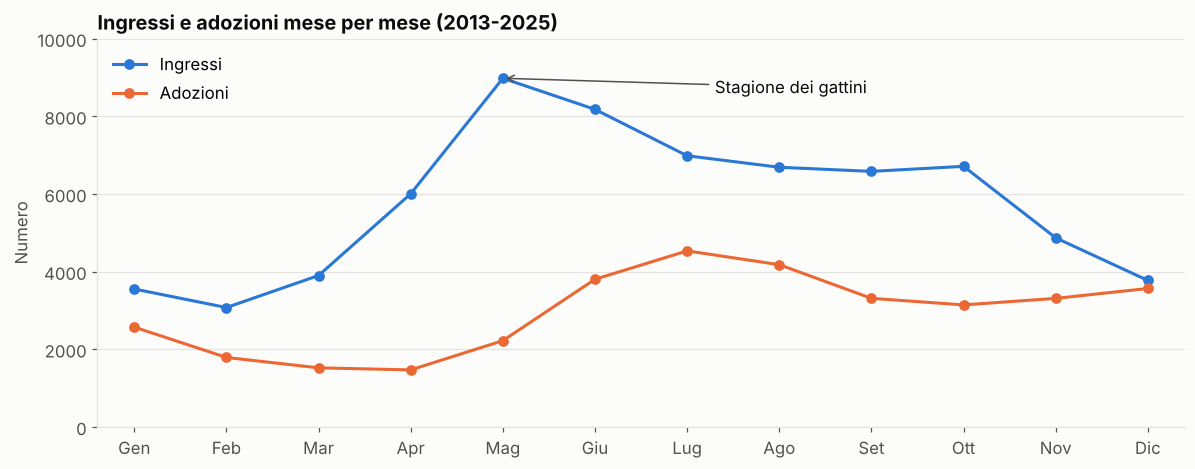

In [5]:
mesi = ['Gen', 'Feb', 'Mar', 'Apr', 'Mag', 'Giu', 'Lug', 'Ago', 'Set', 'Ott', 'Nov', 'Dic']
ing = d.groupby('mese').size(); ado = a.groupby(a['data_uscita'].dt.month).size()
f, ax = plt.subplots(figsize=(11, 4.4))
ax.plot(mesi, ing.values, color=BLU, lw=2, marker='o', ms=6, label='Ingressi')
ax.plot(mesi, ado.values, color='#eb6834', lw=2, marker='o', ms=6, label='Adozioni')
ax.annotate('Stagione dei gattini', xy=(4, ing.values[4]), xytext=(6.3, 8600), color=INK, arrowprops=dict(arrowstyle='->', color=MUTED))
ax.set_title('Ingressi e adozioni mese per mese (2013-2025)'); ax.set_ylabel('Numero'); ax.set_xlim(-0.4, 11.4); ax.set_ylim(0, 10000); ax.grid(axis='x', visible=False)
ax.legend(frameon=False, loc='upper left')
salva(f, '04_stagioni.png')

📌 A **maggio** gli ingressi sono **2,5 volte** quelli di gennaio: è la **stagione dei gattini**.
📌 Le adozioni arrivano **dopo**, a **luglio e agosto**, quando i gattini sono cresciuti.
💡 Il rifugio può prepararsi: più volontari e posti in primavera, campagne di adozione in estate.

## 📈 5. Le adozioni crescono negli anni?

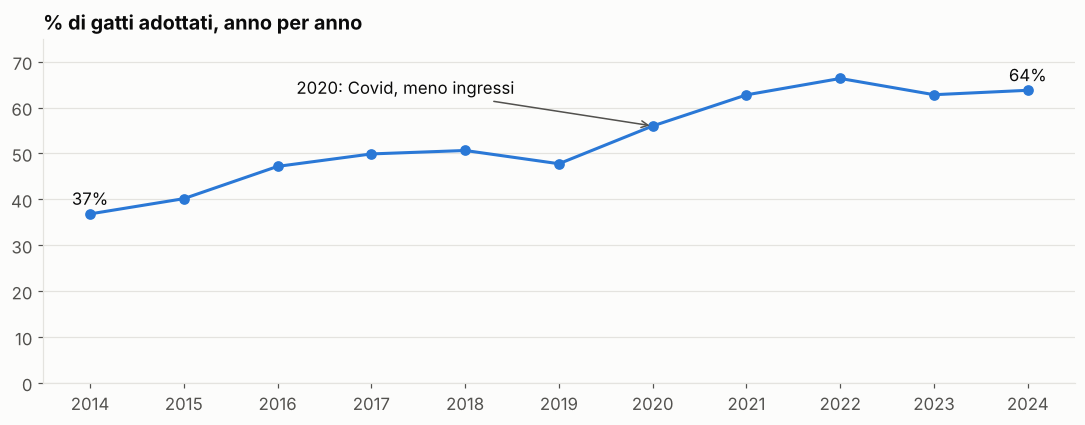

In [6]:
y = c[c['anno'].between(2014, 2024)].groupby('anno')['adottato'].mean() * 100
f, ax = plt.subplots(figsize=(10, 4))
ax.plot(y.index, y.values, color=BLU, lw=2, marker='o', ms=6)
for xx, v in [(2014, y[2014]), (2024, y[2024])]: ax.text(xx, v + 2, f'{v:.0f}%', ha='center', color=INK)
ax.annotate('2020: Covid, meno ingressi', xy=(2020, y[2020]), xytext=(2016.2, 63), color=INK, arrowprops=dict(arrowstyle='->', color=MUTED))
ax.set_title('% di gatti adottati, anno per anno'); ax.set_ylim(0, 75); ax.set_xticks(y.index); ax.grid(axis='x', visible=False)
salva(f, '05_anni.png')

📌 La quota di adozioni è passata dal **37% (2014)** al **64% (2024)**.
📌 Nel **2020** (Covid) sono entrati la metà dei gatti, e da lì le adozioni sono rimaste alte.

## 🏥 6. Il modo in cui arriva il gatto conta?

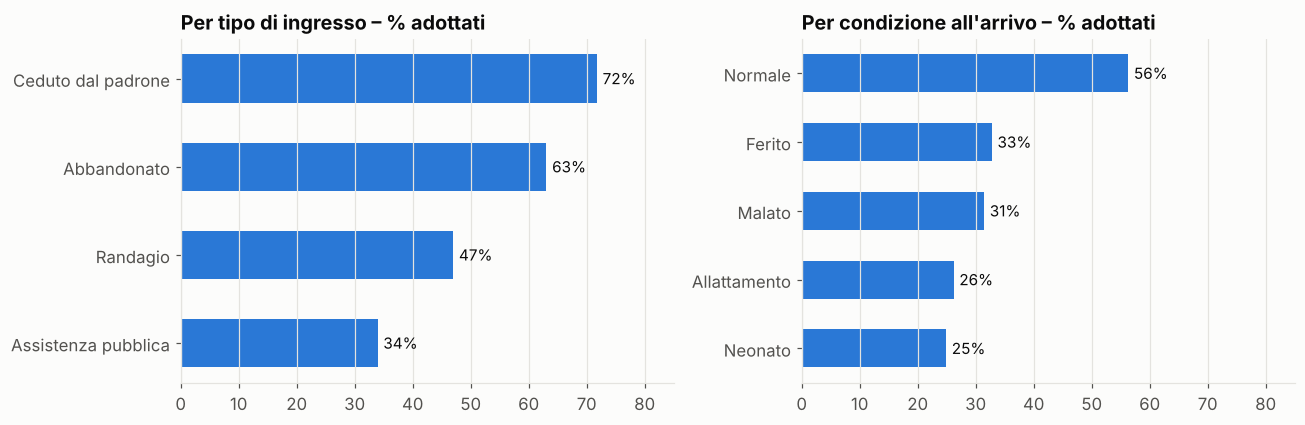

In [7]:
ti = c.groupby('tipo_ingresso')['adottato'].agg(['size', 'mean']).query('size >= 100')['mean'].mul(100).sort_values()
co = c.groupby('condizione')['adottato'].agg(['size', 'mean']).query('size >= 1000')['mean'].mul(100).sort_values()
f, ax = plt.subplots(1, 2, figsize=(12, 4))
for k, (s, tit) in enumerate([(ti, 'Per tipo di ingresso'), (co, 'Per condizione all\'arrivo')]):
    ax[k].barh(s.index, s.values, color=BLU, height=0.55); ax[k].grid(axis='y', visible=False); ax[k].set_xlim(0, 85)
    for i, v in enumerate(s.values): ax[k].text(v + 1, i, f'{v:.0f}%', va='center', fontsize=10, color=INK)
    ax[k].set_title(tit + ' – % adottati')
salva(f, '06_ingresso.png')

📌 I gatti **ceduti dal padrone** vengono adottati molto di più (**72%**) dei **randagi** (**47%**):
spesso sono già abituati a vivere in casa.
📌 Un gatto **ferito** o **malato** viene adottato la metà delle volte rispetto a uno sano.

---
📝 Le conclusioni complete sono in **02_CONCLUSIONI.md**.